2026-09-29 00:39:04.246301: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-29 00:39:03.551795: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-29 00:39:03.694804: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-29 00:39:03.721497: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-29 00:39:03.881219: I tensorflow/core/platform/cpu_feature_guar

TensorFlow version: 2.17.0
Đang tạo dữ liệu demo...
Dataset shape: X=(500, 64, 64, 3), y=(500, 64, 64)


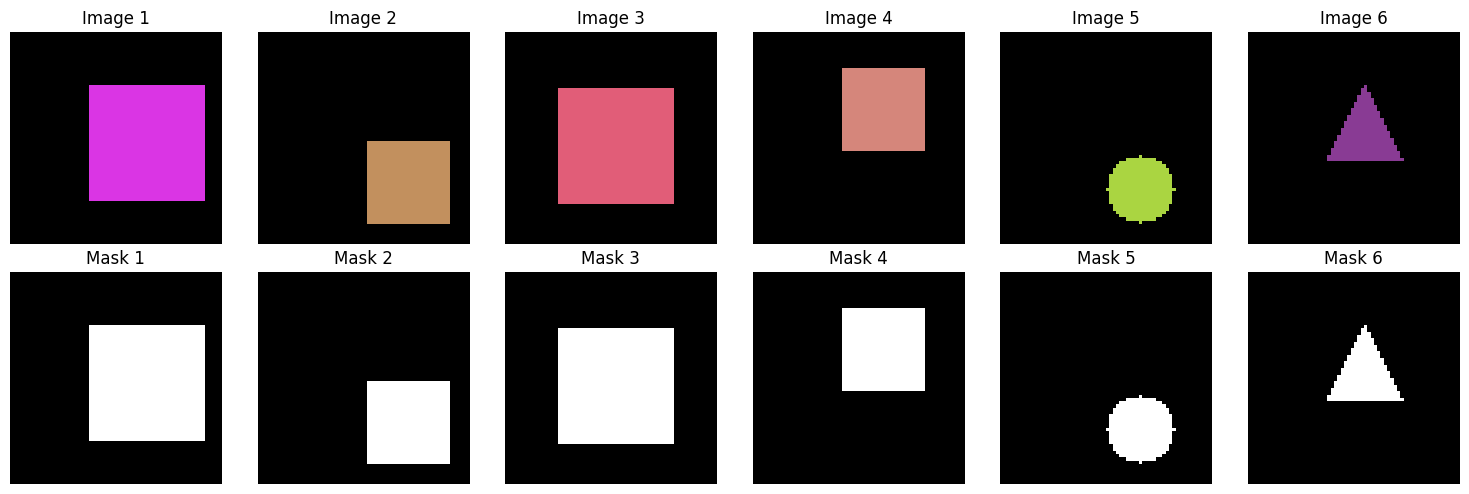

In [1]:
# 1: Setup và Tạo Dữ Liệu Demo
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split

print(f"TensorFlow version: {tf.__version__}")

# Tạo dữ liệu tổng hợp (hình tròn, vuông, tam giác)
def create_synthetic_data(num_samples=500, img_size=64):
    images = []
    masks = []

    for i in range(num_samples):
        img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
        mask = np.zeros((img_size, img_size), dtype=np.uint8)

        shape_type = np.random.choice(['circle', 'square', 'triangle'])
        center_x = np.random.randint(15, img_size - 15)
        center_y = np.random.randint(15, img_size - 15)
        size = np.random.randint(8, 20)
        color = tuple(np.random.randint(50, 255, 3).tolist())

        if shape_type == 'circle':
            cv2.circle(img, (center_x, center_y), size, color, -1)
            cv2.circle(mask, (center_x, center_y), size, 255, -1)
        elif shape_type == 'square':
            cv2.rectangle(img, (center_x - size, center_y - size),
                          (center_x + size, center_y + size), color, -1)
            cv2.rectangle(mask, (center_x - size, center_y - size),
                          (center_x + size, center_y + size), 255, -1)
        else:  # triangle
            pts = np.array([[center_x, center_y - size],
                            [center_x - size, center_y + size],
                            [center_x + size, center_y + size]], np.int32)
            cv2.fillPoly(img, [pts], color)
            cv2.fillPoly(mask, [pts], 255)

        img = img.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        images.append(img)
        masks.append(mask)

    return np.array(images), np.array(masks)

print("Đang tạo dữ liệu demo...")
X, y = create_synthetic_data(num_samples=500, img_size=64)
print(f"Dataset shape: X={X.shape}, y={y.shape}")

# Hiển thị mẫu
def show_samples(X, y, num_samples=6):
    fig, axes = plt.subplots(2, num_samples, figsize=(15, 5))
    for i in range(num_samples):
        axes[0, i].imshow(X[i])
        axes[0, i].set_title(f'Image {i+1}')
        axes[0, i].axis('off')

        axes[1, i].imshow(y[i], cmap='gray')
        axes[1, i].set_title(f'Mask {i+1}')
        axes[1, i].axis('off')
    plt.tight_layout()
    plt.show()

show_samples(X, y)

In [2]:
#2: Xây Dựng U-Net Đơn Giản
def simple_unet(input_size=(64, 64, 3)):
    inputs = Input(input_size)

    # Encoder
    c1 = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    # Bottleneck
    c4 = Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(256, 3, activation='relu', padding='same')(c4)

    # Decoder
    u5 = Conv2DTranspose(128, 2, strides=2, padding='same')(c4)
    u5 = concatenate([u5, c3])
    c5 = Conv2D(128, 3, activation='relu', padding='same')(u5)
    c5 = Conv2D(128, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(64, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c2])
    c6 = Conv2D(64, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(64, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(32, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c1])
    c7 = Conv2D(32, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(32, 3, activation='relu', padding='same')(c7)

    outputs = Conv2D(1, 1, activation='sigmoid')(c7)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

model = simple_unet()
model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

print("Model U-Net Demo đã tạo xong!")
print(f"Tổng parameters: {model.count_params():,}")
model.summary()

I0000 00:00:1790656752.243134   14792 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790656752.438291   14792 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790656752.438407   14792 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790656752.441237   14792 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1790656752.441334   14792 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:0

Model U-Net Demo đã tạo xong!
Tổng parameters: 1,925,601


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 8, 8, 128) │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 8, 8, 256) │    590,080 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    131,200 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,040 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │     32,832 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,925,601 (7.35 MB)

 Trainable params: 1,925,601 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
#3: Training Nhanh
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

y_train = np.expand_dims(y_train, axis=-1)
y_test = np.expand_dims(y_test, axis=-1)

print("Bắt đầu training...")
history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=15,
    validation_data=(X_test, y_test),
    verbose=1
)
print("Training hoàn thành!")

Train: (400, 64, 64, 3), Test: (100, 64, 64, 3)
Bắt đầu training...
Epoch 1/15


I0000 00:00:1790656757.387580   14945 service.cc:146] XLA service 0x59467e68ebc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790656757.387634   14945 service.cc:154]   StreamExecutor device (0): NVIDIA RTX 3500 Ada Generation Laptop GPU, Compute Capability 8.9
2026-09-29 00:39:17.491169: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-09-29 00:39:18.172730: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907


 3/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8564 - loss: 0.6911 

I0000 00:00:1790656768.452381   14945 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/13 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.9154 - loss: 0.5274 - val_accuracy: 0.9329 - val_loss: 0.4142
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9487 - loss: 0.2752 - val_accuracy: 0.9553 - val_loss: 0.1552
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9694 - loss: 0.0871 - val_accuracy: 0.9852 - val_loss: 0.0508
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9894 - loss: 0.0306 - val_accuracy: 0.9923 - val_loss: 0.0201
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9943 - loss: 0.0165 - val_accuracy: 0.9954 - val_loss: 0.0120
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9963 - loss: 0.0102 - val_accuracy: 0.9971 - val_loss: 0.0080
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9979 - loss: 0.0063 - val_accuracy: 0.9985 - val_loss: 0.0048
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9987 - loss: 0.0043 - val_accuracy: 0.9988 - val_loss: 0.0

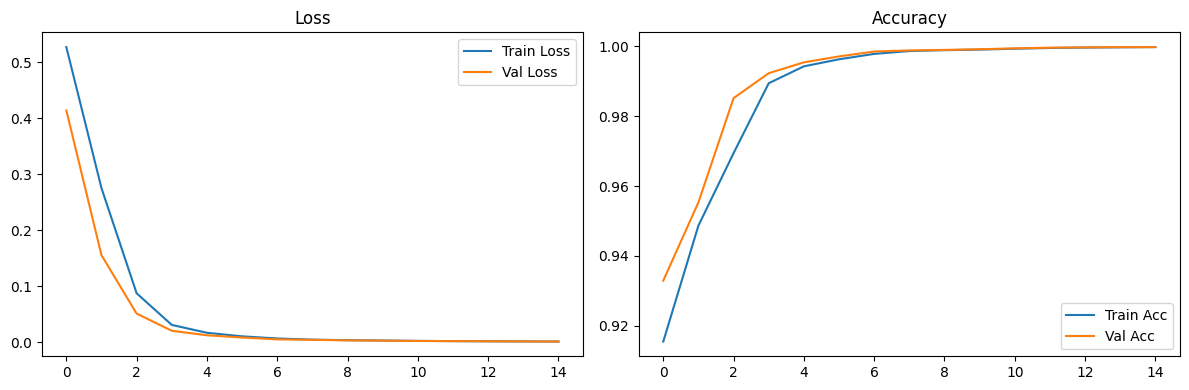

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


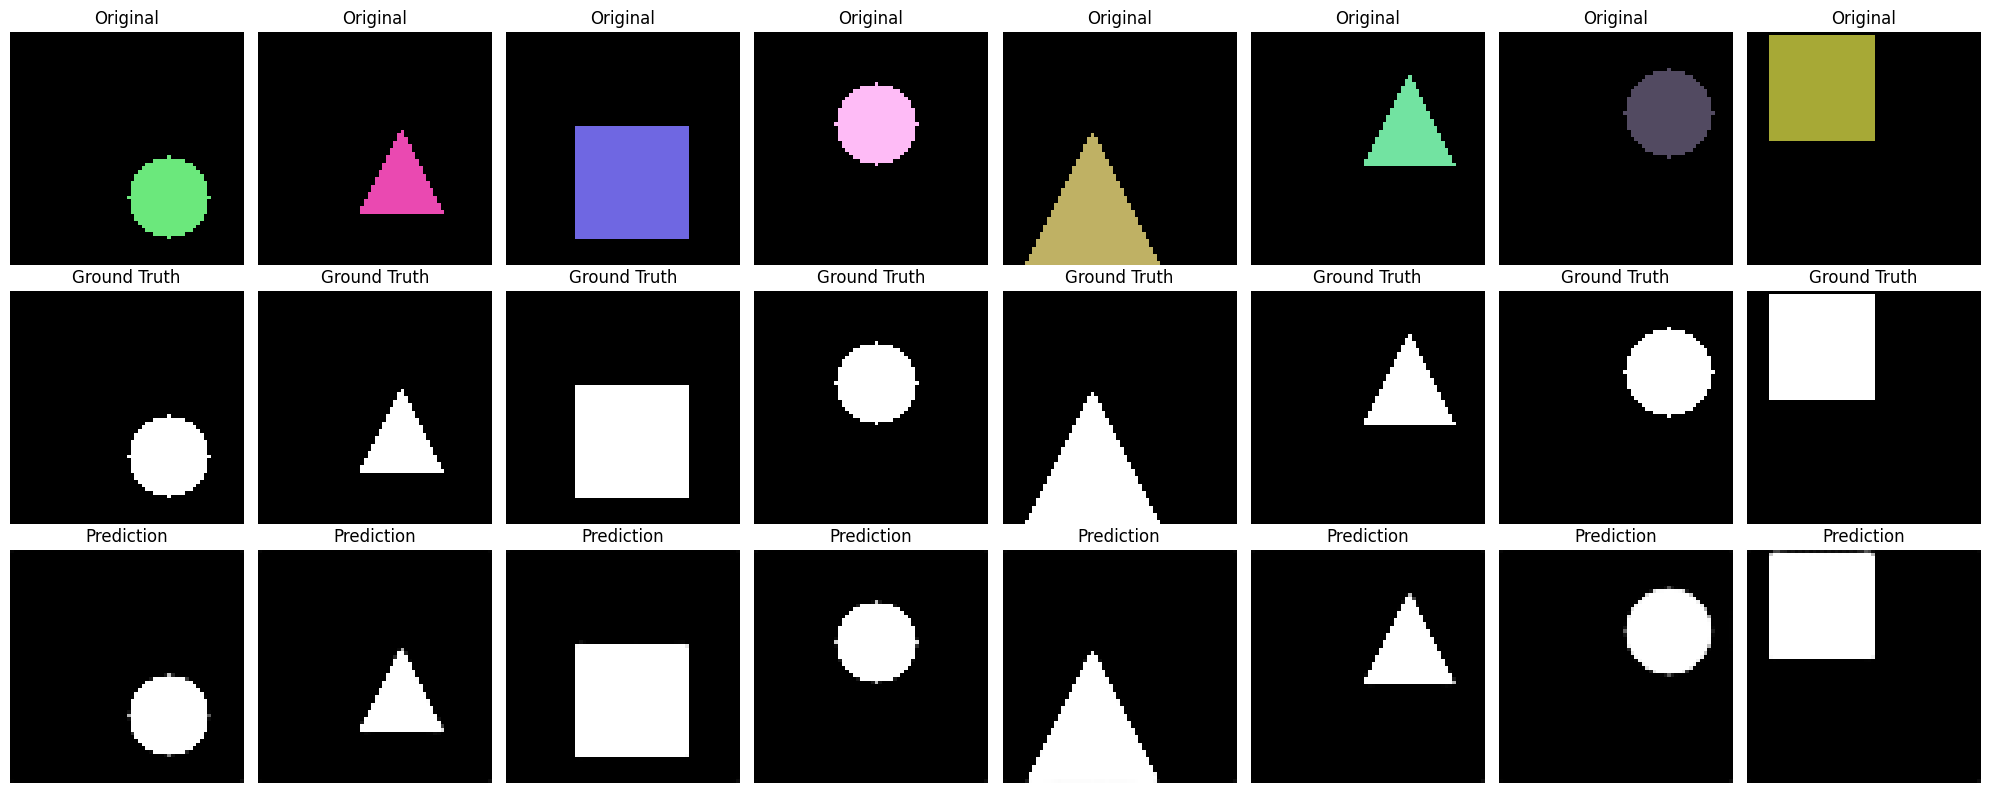

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step
IoU Score: 0.9982
Test Accuracy: 0.9998


In [4]:
#4: Đánh Giá và Visualization
def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title('Loss')
    ax1.legend()

    ax2.plot(history.history['accuracy'], label='Train Acc')
    ax2.plot(history.history['val_accuracy'], label='Val Acc')
    ax2.set_title('Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

def show_predictions(model, X_test, y_test, num_samples=8):
    predictions = model.predict(X_test[:num_samples])
    fig, axes = plt.subplots(3, num_samples, figsize=(20, 8))

    for i in range(num_samples):
        axes[0, i].imshow(X_test[i])
        axes[0, i].set_title('Original')
        axes[0, i].axis('off')

        axes[1, i].imshow(y_test[i].squeeze(), cmap='gray')
        axes[1, i].set_title('Ground Truth')
        axes[1, i].axis('off')

        pred = predictions[i].squeeze()
        axes[2, i].imshow(pred, cmap='gray')
        axes[2, i].set_title('Prediction')
        axes[2, i].axis('off')

    plt.tight_layout()
    plt.show()

show_predictions(model, X_test, y_test)

def calculate_iou(y_true, y_pred, threshold=0.5):
    y_pred_binary = (y_pred > threshold).astype(np.float32)
    intersection = np.sum(y_true * y_pred_binary, axis=(1, 2))
    union = np.sum(y_true, axis=(1, 2)) + np.sum(y_pred_binary, axis=(1, 2)) - intersection
    iou = intersection / (union + 1e-7)
    return np.mean(iou)

test_predictions = model.predict(X_test)
iou_score = calculate_iou(y_test.squeeze(), test_predictions.squeeze())

print(f"IoU Score: {iou_score:.4f}")
print(f"Test Accuracy: {model.evaluate(X_test, y_test, verbose=0)[1]:.4f}")

--- Bài tập 1: Thử nghiệm threshold ---
Threshold 0.3: IoU = 0.9992
Threshold 0.5: IoU = 0.9982
Threshold 0.7: IoU = 0.9966
Threshold 0.9: IoU = 0.9928

--- Bài tập 2: Test với dữ liệu mới ---
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step 
IoU trên dữ liệu mới: 0.9983
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


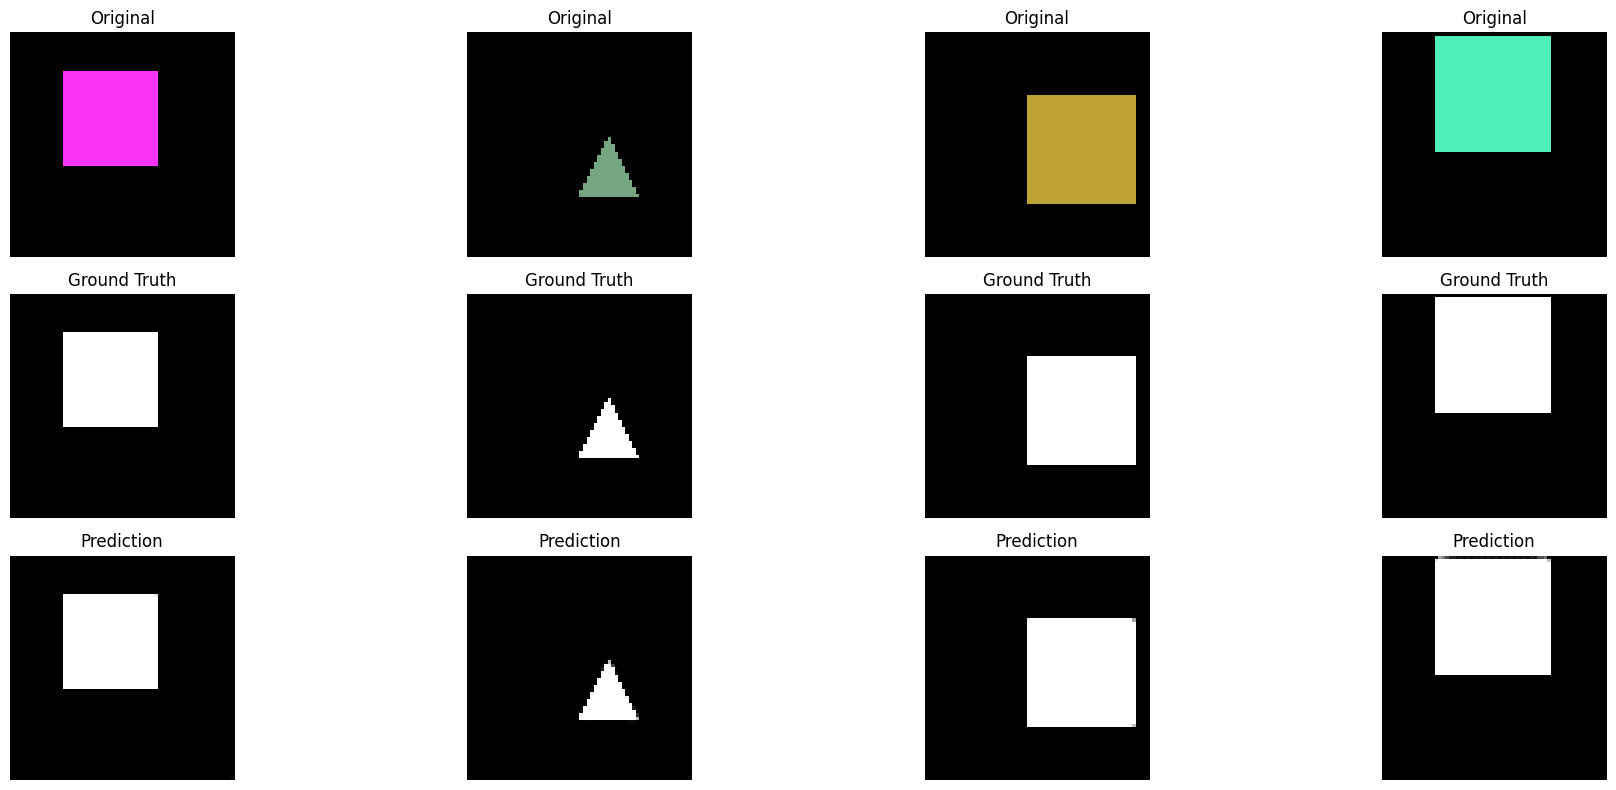


--- Bài tập 3: Model nhỏ hơn (Tiny U-Net) ---
Tiny U-Net params: 56,977
Simple U-Net params: 1,925,601
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Tiny U-Net Test IoU: 0.9955


In [5]:
# 5: Bài Tập Thực Hành Lab 1

# Bài tập 1: Thử nghiệm threshold
print("--- Bài tập 1: Thử nghiệm threshold ---")
thresholds = [0.3, 0.5, 0.7, 0.9]
for thresh in thresholds:
    iou = calculate_iou(y_test.squeeze(), test_predictions.squeeze(), thresh)
    print(f"Threshold {thresh}: IoU = {iou:.4f}")

# Bài tập 2: Test với dữ liệu mới
print("\n--- Bài tập 2: Test với dữ liệu mới ---")
X_new, y_new = create_synthetic_data(num_samples=50, img_size=64)
y_new = np.expand_dims(y_new, axis=-1)

new_predictions = model.predict(X_new)
new_iou = calculate_iou(y_new.squeeze(), new_predictions.squeeze())
print(f"IoU trên dữ liệu mới: {new_iou:.4f}")

show_predictions(model, X_new, y_new, num_samples=4)

# Bài tập 3: So sánh với tiny_unet
print("\n--- Bài tập 3: Model nhỏ hơn (Tiny U-Net) ---")
def tiny_unet(input_size=(64, 64, 3)):
    inputs = Input(input_size)
    c1 = Conv2D(16, 3, activation='relu', padding='same')(inputs)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(32, 3, activation='relu', padding='same')(p1)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(64, 3, activation='relu', padding='same')(p2)

    u4 = Conv2DTranspose(32, 2, strides=2, padding='same')(c3)
    u4 = concatenate([u4, c2])
    c4 = Conv2D(32, 3, activation='relu', padding='same')(u4)

    u5 = Conv2DTranspose(16, 2, strides=2, padding='same')(c4)
    u5 = concatenate([u5, c1])
    c5 = Conv2D(16, 3, activation='relu', padding='same')(u5)

    outputs = Conv2D(1, 1, activation='sigmoid')(c5)
    return Model(inputs=[inputs], outputs=[outputs])

tiny_model = tiny_unet()
tiny_model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

print(f"Tiny U-Net params: {tiny_model.count_params():,}")
print(f"Simple U-Net params: {model.count_params():,}")

tiny_history = tiny_model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=15,
    validation_data=(X_test, y_test),
    verbose=0
)

tiny_preds = tiny_model.predict(X_test)
tiny_iou = calculate_iou(y_test.squeeze(), tiny_preds.squeeze())
print(f"Tiny U-Net Test IoU: {tiny_iou:.4f}")

In [6]:
# Setup và Tải Dữ Liệu
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
import os
import glob

print(f"TensorFlow version: {tf.__version__}")

# Tải Oxford Pets Dataset
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz

!tar -xf images.tar.gz
!tar -xf annotations.tar.gz

print("Dataset đã được tải xong!")

IMAGE_PATH = 'images/'
MASK_PATH = 'annotations/trimaps/'

image_files = sorted(glob.glob(IMAGE_PATH + '*.jpg'))
mask_files = sorted(glob.glob(MASK_PATH + '*.png'))

print(f"Tổng số ảnh: {len(image_files)}")
print(f"Tổng số mask: {len(mask_files)}")

TensorFlow version: 2.17.0
Dataset đã được tải xong!
Tổng số ảnh: 7390
Tổng số mask: 7390


Đang xử lý dữ liệu...
Đã xử lý: 100/500
Đã xử lý: 200/500
Đã xử lý: 300/500
Đã xử lý: 400/500
Đã xử lý: 500/500
Dataset final shape: X=(500, 128, 128, 3), y=(500, 128, 128)


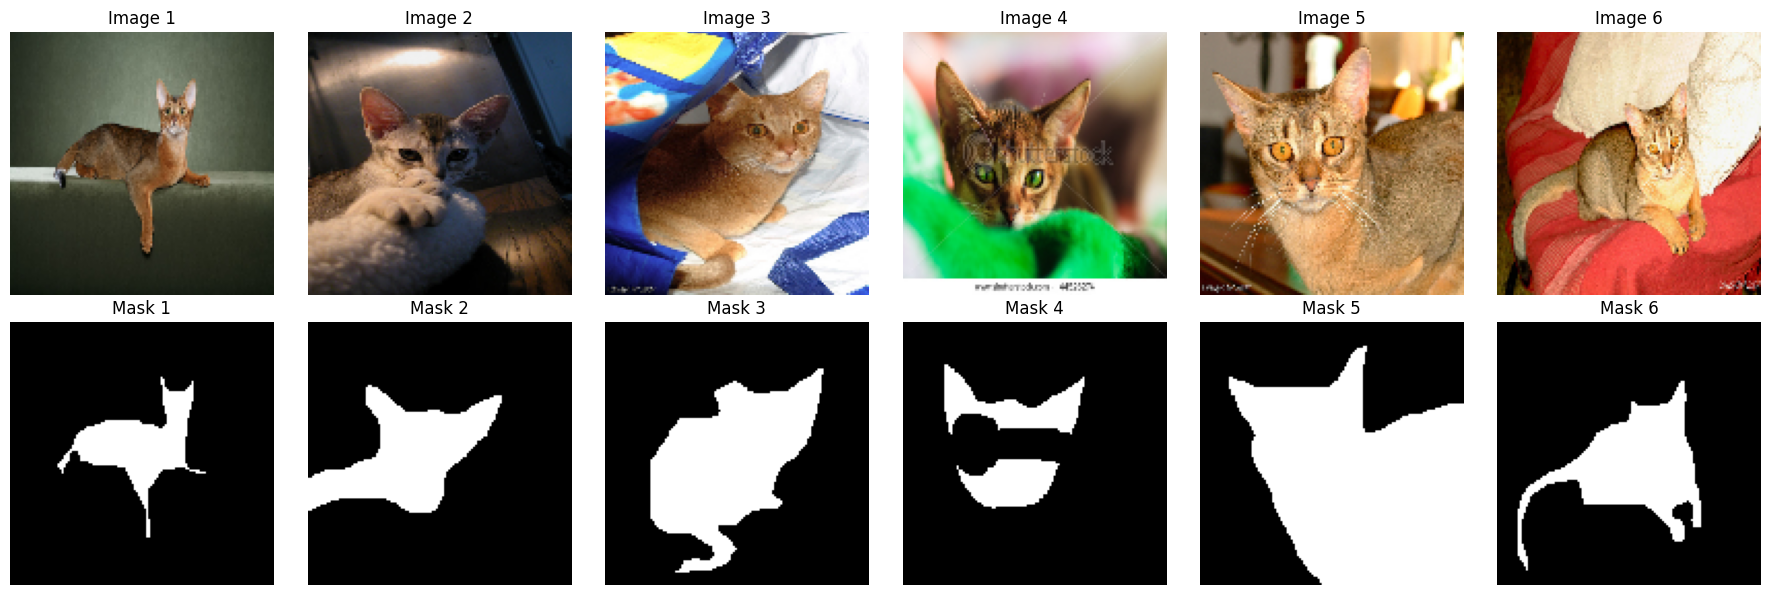

In [7]:
# Tiền Xử Lý Dữ Liệu
IMG_HEIGHT = 128
IMG_WIDTH = 128
MAX_SAMPLES = 500

def preprocess_data(image_path, mask_path, img_size=(IMG_HEIGHT, IMG_WIDTH)):
    try:
        image = cv2.imread(image_path)
        if image is None:
            return None, None
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, img_size)
        image = image.astype(np.float32) / 255.0

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            return None, None
        mask = cv2.resize(mask, img_size, interpolation=cv2.INTER_NEAREST)

        # Convert trimap to binary mask (1=pet, 0=background)
        binary_mask = (mask == 1).astype(np.float32)

        return image, binary_mask
    except Exception:
        return None, None

def create_limited_dataset(image_files, max_samples=500):
    images = []
    masks = []
    count = 0

    print("Đang xử lý dữ liệu...")
    for img_path in image_files:
        if count >= max_samples:
            break

        img_name = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = f"{MASK_PATH}{img_name}.png"

        if os.path.exists(mask_path):
            img, mask = preprocess_data(img_path, mask_path)
            if img is not None and mask is not None:
                images.append(img)
                masks.append(mask)
                count += 1
                if count % 100 == 0:
                    print(f"Đã xử lý: {count}/{max_samples}")

    return np.array(images), np.array(masks)

X, y = create_limited_dataset(image_files, MAX_SAMPLES)
print(f"Dataset final shape: X={X.shape}, y={y.shape}")

def display_samples(X, y, num_samples=6):
    fig, axes = plt.subplots(2, num_samples, figsize=(18, 6))
    for i in range(num_samples):
        axes[0, i].imshow(X[i])
        axes[0, i].set_title(f'Image {i+1}')
        axes[0, i].axis('off')

        axes[1, i].imshow(y[i], cmap='gray')
        axes[1, i].set_title(f'Mask {i+1}')
        axes[1, i].axis('off')
    plt.tight_layout()
    plt.show()

display_samples(X, y)

In [8]:
#3: Xây Dựng Compact U-Net
def compact_unet(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    inputs = Input(input_shape)

    # Encoder
    c1 = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    # Bottleneck
    c4 = Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(256, 3, activation='relu', padding='same')(c4)

    # Decoder
    u5 = Conv2DTranspose(128, 2, strides=2, padding='same')(c4)
    u5 = concatenate([u5, c3])
    c5 = Conv2D(128, 3, activation='relu', padding='same')(u5)
    c5 = Conv2D(128, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(64, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c2])
    c6 = Conv2D(64, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(64, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(32, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c1])
    c7 = Conv2D(32, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(32, 3, activation='relu', padding='same')(c7)

    outputs = Conv2D(1, 1, activation='sigmoid')(c7)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

model = compact_unet()
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(f"Model parameters: {model.count_params():,}")
print("Model đã sẵn sàng để training!")

Model parameters: 1,925,601
Model đã sẵn sàng để training!


In [9]:
# 4: Training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_train = np.expand_dims(y_train, axis=-1)
y_test = np.expand_dims(y_test, axis=-1)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss'),
    ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-6, monitor='val_loss')
]

print("Bắt đầu training...")
history = model.fit(
    X_train, y_train,
    batch_size=16,
    epochs=20,
    validation_data=(X_test, y_test),
    callbacks=callbacks,
    verbose=1
)
print("Training hoàn thành!")

Train: (400, 128, 128, 3), Test: (100, 128, 128, 3)
Bắt đầu training...
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - accuracy: 0.7089 - loss: 0.6053 - val_accuracy: 0.7165 - val_loss: 0.5711 - learning_rate: 0.0010
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7089 - loss: 0.5663 - val_accuracy: 0.7165 - val_loss: 0.5855 - learning_rate: 0.0010
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7090 - loss: 0.5300 - val_accuracy: 0.7223 - val_loss: 0.4570 - learning_rate: 0.0010
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7670 - loss: 0.4759 - val_accuracy: 0.7732 - val_loss: 0.4714 - learning_rate: 0.0010
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7590 - loss: 0.4741 - val_accuracy: 0.8032 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.7877 - loss: 0.4539 - val_accuracy: 0.8153 - val_loss: 0.4151 - learning_rate: 0.0010
Epoch 7/20
25/25 ━━━

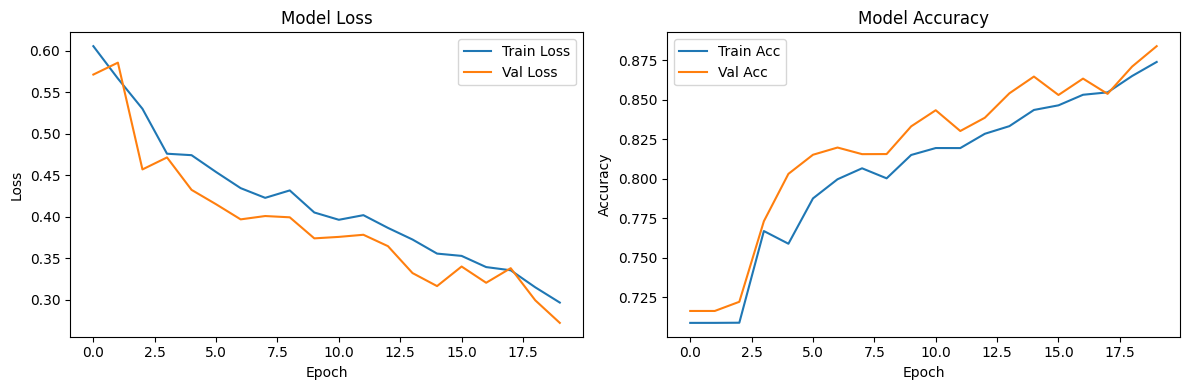

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


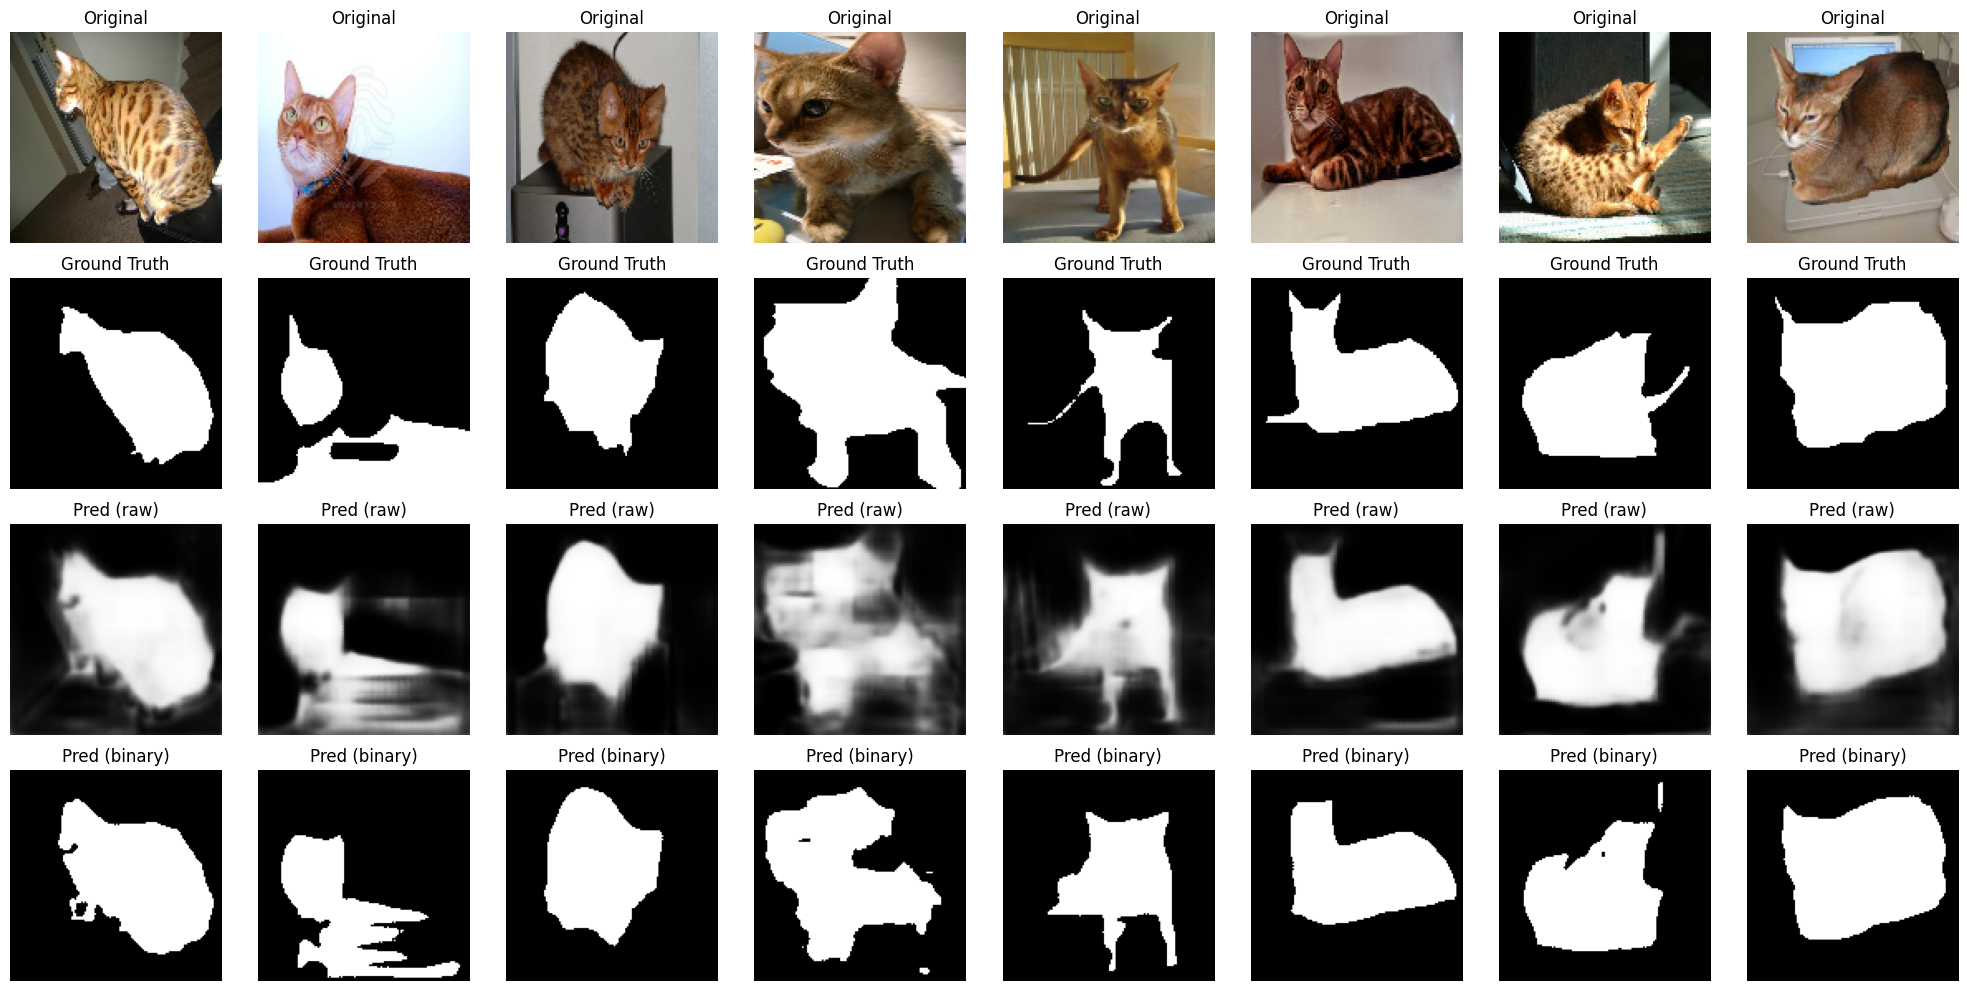

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step
IoU Score: 0.6566
Test Accuracy: 0.8840


In [10]:
#  Đánh Giá và Visualization
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    ax2.plot(history.history['accuracy'], label='Train Acc')
    ax2.plot(history.history['val_accuracy'], label='Val Acc')
    ax2.set_title('Model Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)

def show_predictions(model, X_test, y_test, num_samples=8):
    predictions = model.predict(X_test[:num_samples])
    fig, axes = plt.subplots(4, num_samples, figsize=(20, 10))

    for i in range(num_samples):
        axes[0, i].imshow(X_test[i])
        axes[0, i].set_title('Original')
        axes[0, i].axis('off')

        axes[1, i].imshow(y_test[i].squeeze(), cmap='gray')
        axes[1, i].set_title('Ground Truth')
        axes[1, i].axis('off')

        pred_raw = predictions[i].squeeze()
        axes[2, i].imshow(pred_raw, cmap='gray')
        axes[2, i].set_title('Pred (raw)')
        axes[2, i].axis('off')

        pred_binary = (pred_raw > 0.5).astype(np.float32)
        axes[3, i].imshow(pred_binary, cmap='gray')
        axes[3, i].set_title('Pred (binary)')
        axes[3, i].axis('off')

    plt.tight_layout()
    plt.show()

show_predictions(model, X_test, y_test)

def calculate_iou(y_true, y_pred, threshold=0.5):
    y_pred_binary = (y_pred > threshold).astype(np.float32)
    intersection = np.sum(y_true * y_pred_binary, axis=(1, 2))
    union = np.sum(y_true, axis=(1, 2)) + np.sum(y_pred_binary, axis=(1, 2)) - intersection
    iou = intersection / (union + 1e-7)
    return np.mean(iou)

test_predictions = model.predict(X_test)
iou_score = calculate_iou(y_test.squeeze(), test_predictions.squeeze())
test_acc = model.evaluate(X_test, y_test, verbose=0)[1]

print(f"IoU Score: {iou_score:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")